In [8]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
sns.set_theme(style="whitegrid")

CORE = ["tensile_strength_MPa", "yield_strength_MPa", "elongation_pct",
        "youngs_modulus_GPa", "density_g_cm3"]

X = pd.read_csv("../data/processed/materials_scaled.csv", index_col=0)
meta = pd.read_csv("../data/processed/materials_features.csv").set_index("label").loc[X.index]
assert (X.index == meta.index).all()
print(X.shape, meta.shape)

(1235, 5) (1235, 21)


In [9]:
rows = []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_),
        "davies_bouldin": davies_bouldin_score(X, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
    })
sweep = pd.DataFrame(rows).set_index("k")
display(sweep.round(3))

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,3232.190,0.550,0.741,1122.609
3,2010.313,0.416,0.861,1276.143
4,1555.576,0.424,0.795,1218.522
5,1346.761,0.403,0.963,1102.411
6,1159.233,0.347,1.021,1063.527
7,996.745,0.357,0.929,1063.277
8,841.031,0.383,0.850,1111.698
9,751.306,0.370,0.878,1106.315
10,668.720,0.383,0.860,1120.747


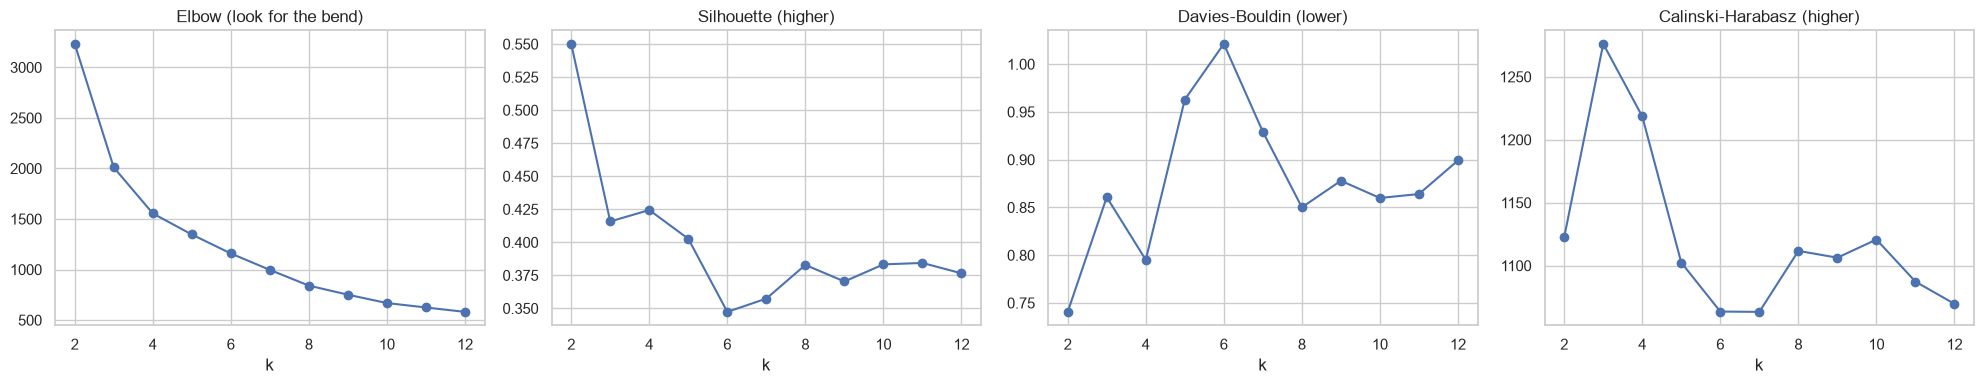

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
titles = {"inertia": "Elbow (look for the bend)", "silhouette": "Silhouette (higher)",
          "davies_bouldin": "Davies-Bouldin (lower)", "calinski_harabasz": "Calinski-Harabasz (higher)"}
for ax, (col, title) in zip(axes, titles.items()):
    ax.plot(sweep.index, sweep[col], marker="o"); ax.set_title(title); ax.set_xlabel("k")
plt.tight_layout(); plt.savefig("../figures/05_choose_k.png", dpi=150); plt.show()

In [17]:
CANDIDATES = [3, 4, 5]
for K in CANDIDATES:
    km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
    meta[f"km{K}"] = km.labels_
    print(f"\n===== K = {K}: family (rows) vs cluster (columns) =====")
    print(pd.crosstab(meta["family"], meta[f"km{K}"]))

PROFILE = CORE + ["specific_strength"]
for K in CANDIDATES:
    prof = meta.groupby(f"km{K}")[PROFILE].median().round(1)
    prof["n"] = meta[f"km{K}"].value_counts().sort_index()
    print(f"\n===== K = {K}: median properties per cluster =====")
    display(prof)


===== K = 3: family (rows) vs cluster (columns) =====
km3                0    1    2
family                        
Aluminium          0  197    0
Cast iron         28    3   10
Copper alloy       7    4  155
Magnesium          0   30    0
Stainless steel   41    0   76
Steel            455    0  229

===== K = 4: family (rows) vs cluster (columns) =====
km4                0    1    2    3
family                             
Aluminium          0    0  197    0
Cast iron         21    1    2   17
Copper alloy       5  133    4   24
Magnesium          0    0   30    0
Stainless steel   30    0    0   87
Steel            280    3    0  401

===== K = 5: family (rows) vs cluster (columns) =====
km5                0    1    2    3   4
family                                 
Aluminium          0  144    0    0  53
Cast iron         19    0    1   19   2
Copper alloy      24    0  133    5   4
Magnesium          0   17    0    0  13
Stainless steel   87    0    0   30   0
Steel            40

,tensile_strength_MPa,yield_strength_MPa,elongation_pct,youngs_modulus_GPa,density_g_cm3,specific_strength,n
km3,,,,,,,
0,785.0,540.0,12.0,206.0,7.9,100.4,531
1,241.0,172.0,10.0,73.0,2.7,91.9,234
2,450.0,241.0,25.0,206.0,7.9,56.2,470



===== K = 4: median properties per cluster =====


,tensile_strength_MPa,yield_strength_MPa,elongation_pct,youngs_modulus_GPa,density_g_cm3,specific_strength,n
km4,,,,,,,
0,925.0,685.0,11.0,206.0,7.9,117.7,336
1,310.0,131.0,35.0,105.0,8.8,35.6,137
2,241.0,172.0,10.0,73.0,2.7,91.9,233
3,540.0,315.0,20.0,206.0,7.9,68.7,529



===== K = 5: median properties per cluster =====


,tensile_strength_MPa,yield_strength_MPa,elongation_pct,youngs_modulus_GPa,density_g_cm3,specific_strength,n
km5,,,,,,,
0,540.0,315.0,20.0,206.0,7.9,68.7,535
1,262.0,179.0,12.0,73.0,2.7,107.4,161
2,310.0,131.0,35.0,105.0,8.8,35.6,137
3,929.5,685.0,11.0,206.0,7.9,118.3,330
4,221.0,162.0,3.2,73.0,2.7,80.6,72


In [16]:
def stability(K, n_runs=30):
    ref = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X).labels_
    aris = [adjusted_rand_score(ref, KMeans(n_clusters=K, n_init=1, random_state=s).fit(X).labels_)
            for s in range(n_runs)]
    return round(np.mean(aris), 3), round(np.min(aris), 3)

stab = pd.DataFrame({K: stability(K) for K in [3, 4, 5, 6]}, index=["mean ARI", "min ARI"]).T
stab

,mean ARI,min ARI
3,0.972,0.855
4,0.863,0.435
5,0.796,0.397
6,0.698,0.490


In [18]:
def reproducibility(K, seeds=range(10)):
    ref = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X).labels_
    aris = [adjusted_rand_score(ref, KMeans(n_clusters=K, n_init=20, random_state=s).fit(X).labels_)
            for s in seeds]
    return round(np.mean(aris), 3), round(np.min(aris), 3)

repro = pd.DataFrame({K: reproducibility(K) for K in [3, 4, 5, 6]},
                     index=["mean ARI", "min ARI"]).T
repro

,mean ARI,min ARI
3,1.000,1.000
4,0.993,0.984
5,0.993,0.979
6,0.941,0.795


In [19]:
K = 4
km_final = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
meta["cluster"] = km_final.labels_

# name clusters from their median properties, so the names don't depend on label numbering
prof = meta.groupby("cluster")[CORE].median()
light  = prof["density_g_cm3"].idxmin()
copper = prof["density_g_cm3"].idxmax()
rest   = [c for c in prof.index if c not in (light, copper)]
high   = prof.loc[rest, "tensile_strength_MPa"].idxmax()
medium = [c for c in rest if c != high][0]
names = {light: "Light alloys (Al, Mg)", copper: "Ductile copper alloys",
         high: "High-strength steels", medium: "Medium-strength ductile steels"}
meta["cluster_name"] = meta["cluster"].map(names)

print(meta["cluster_name"].value_counts())
display(pd.crosstab(meta["cluster_name"], meta["family"]))

cluster_name
Medium-strength ductile steels    529
High-strength steels              336
Light alloys (Al, Mg)             233
Ductile copper alloys             137
Name: count, dtype: int64


family,Aluminium,Cast iron,Copper alloy,Magnesium,Stainless steel,Steel
cluster_name,,,,,,
Ductile copper alloys,0,1,133,0,0,3
High-strength steels,0,21,5,0,30,280
"Light alloys (Al, Mg)",197,2,4,30,0,0
Medium-strength ductile steels,0,17,24,0,87,401


Mean silhouette: 0.424
                                mean   min  n_negative
cluster_name                                          
Ductile copper alloys           0.45 -0.03           2
High-strength steels            0.41 -0.06           7
Light alloys (Al, Mg)           0.45 -0.01           2
Medium-strength ductile steels  0.42  0.00           0


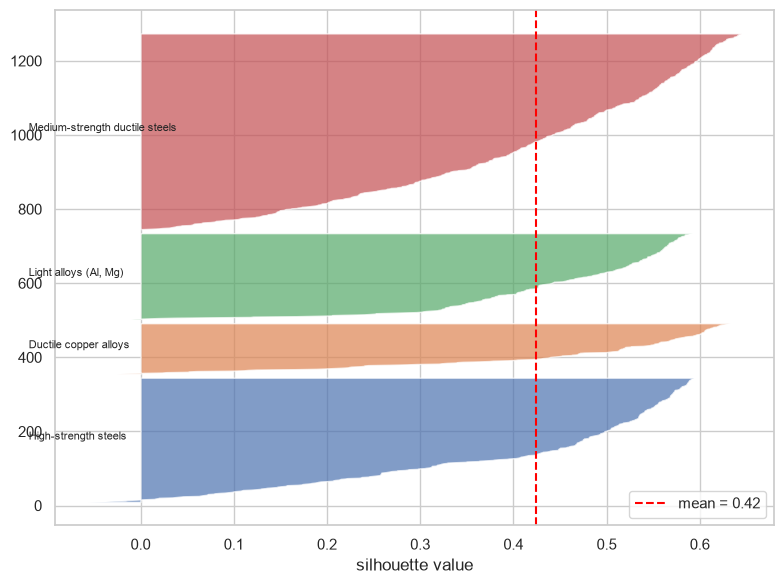

,family,cluster_name,tensile_strength_MPa,yield_strength_MPa,elongation_pct,youngs_modulus_GPa,density_g_cm3,silhouette
label,,,,,,,,
NF A70-2 | n/a,Steel,High-strength steels,690.0,365.0,10.00,206.0,7.86,-0.06
BS CEW3BK | n/a,Steel,High-strength steels,450.0,360.0,6.00,206.0,7.86,-0.04
Steel 25 GOST 1050-88 | Cold working,Steel,High-strength steels,540.0,350.0,7.00,198.0,7.82,-0.03
Steel 30 GOST 1050-88 | Cold working,Steel,High-strength steels,560.0,340.0,7.00,200.0,7.85,-0.03
BS CR4GP | n/a,Steel,Ductile copper alloys,280.0,140.0,30.40,206.0,7.86,-0.03
Malleable cast iron 50-5 | n/a,Cast iron,High-strength steels,490.0,290.0,5.00,160.0,7.16,-0.02
Nodular cast iron | n/a #1233,Cast iron,High-strength steels,500.0,320.0,5.62,169.0,7.16,-0.01
BS CR3GP | n/a,Steel,Ductile copper alloys,280.0,140.0,32.00,206.0,7.86,-0.01
Leaded Tin Bronze C92800 | n/a,Copper alloy,"Light alloys (Al, Mg)",276.0,207.0,1.00,120.0,8.80,-0.01


In [20]:
sil = silhouette_samples(X, km_final.labels_)
meta["silhouette"] = sil
print("Mean silhouette:", sil.mean().round(3))
print(meta.groupby("cluster_name")["silhouette"].agg(
      mean="mean", min="min", n_negative=lambda s: (s < 0).sum()).round(2))

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
for c in sorted(meta["cluster"].unique()):
    s = np.sort(sil[km_final.labels_ == c])
    y_upper = y_lower + len(s)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, s, alpha=0.7)
    ax.text(-0.12, y_lower + 0.5 * len(s), names[c], fontsize=8)
    y_lower = y_upper + 10
ax.axvline(sil.mean(), color="red", ls="--", label=f"mean = {sil.mean():.2f}")
ax.set_xlabel("silhouette value"); ax.legend()
plt.tight_layout(); plt.savefig("../figures/05_silhouette_plot.png", dpi=150); plt.show()

meta.nsmallest(15, "silhouette")[["family", "cluster_name"] + CORE + ["silhouette"]].round(2)

In [21]:
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
gmm = GaussianMixture(n_components=K, covariance_type="diag", reg_covar=1e-3,
                      n_init=10, random_state=42).fit(X)

labels = {"K-Means": meta["cluster"].values,
          "Agglomerative (Ward)": agg.labels_,
          "GMM (diag)": gmm.predict(X)}
rows = []
for name, lab in labels.items():
    rows.append({"method": name,
                 "silhouette": silhouette_score(X, lab),
                 "davies_bouldin": davies_bouldin_score(X, lab),
                 "calinski_harabasz": calinski_harabasz_score(X, lab),
                 "ARI vs K-Means": adjusted_rand_score(labels["K-Means"], lab)})
display(pd.DataFrame(rows).set_index("method").round(3))
display(pd.crosstab(meta["cluster_name"], agg.labels_, rownames=["K-Means"], colnames=["Ward"]))

,silhouette,davies_bouldin,calinski_harabasz,ARI vs K-Means
method,,,,
K-Means,0.424,0.795,1218.522,1.000
Agglomerative (Ward),0.395,0.826,1113.093,0.745
GMM (diag),0.338,1.236,703.085,0.484


Ward,0,1,2,3
K-Means,,,,
Ductile copper alloys,2,0,25,110
High-strength steels,333,0,3,0
"Light alloys (Al, Mg)",6,227,0,0
Medium-strength ductile steels,78,0,451,0


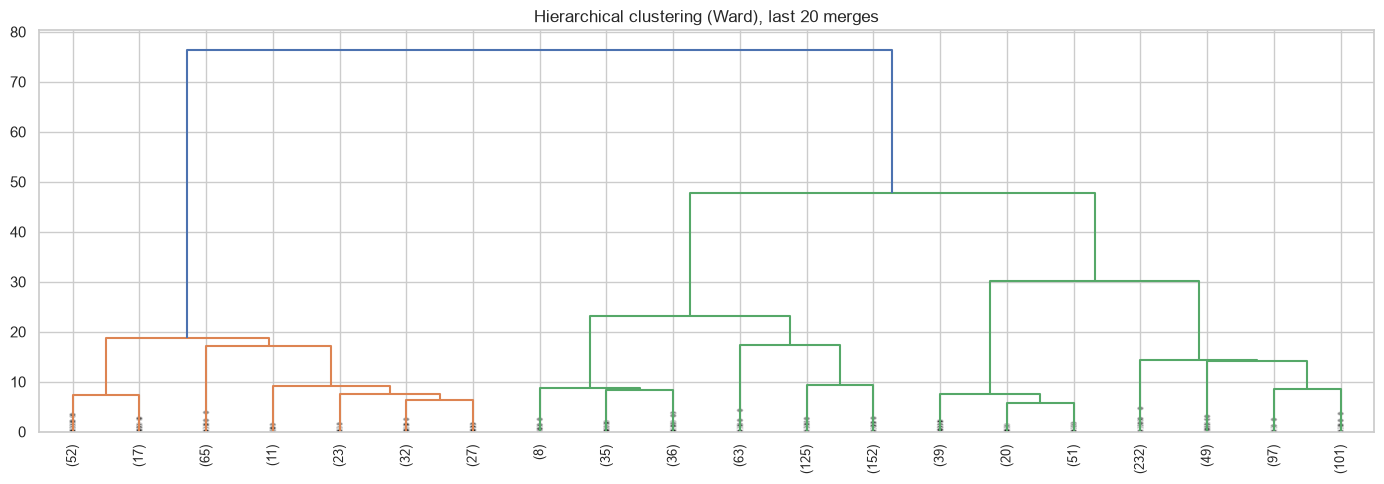

Saved: (1235, 29)


In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram
Zl = linkage(X, method="ward")
plt.figure(figsize=(14, 5))
dendrogram(Zl, truncate_mode="lastp", p=20, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title("Hierarchical clustering (Ward), last 20 merges")
plt.tight_layout(); plt.savefig("../figures/05_dendrogram.png", dpi=150); plt.show()

import joblib
meta.to_csv("../data/processed/materials_clustered.csv")
joblib.dump(km_final, "../data/processed/kmeans_final.joblib")
print("Saved:", meta.shape)

In [24]:
import joblib
scaler = joblib.load("../data/processed/scaler.joblib")
exc = pd.read_csv("../data/processed/materials_excluded_grey_iron.csv")
exc["label"] = exc["material"] + " | " + exc["condition"].astype("object").fillna("n/a").astype(str) + " [post-hoc]"
print("Excluded rows:", len(exc))

Z = scaler.transform(np.log10(exc[CORE]))              # same scaling as the model data
use = [i for i, c in enumerate(CORE) if c != "elongation_pct"]   # ignore the assumed elongation
Z_use = Z[:, use]
cent_use = km_final.cluster_centers_[:, use]
d2 = ((Z_use[:, None, :] - cent_use[None, :, :]) ** 2).sum(axis=2)

exc["cluster"] = d2.argmin(axis=1)
exc["cluster_name"] = exc["cluster"].map(names)
exc["dist_to_nearest"] = np.sqrt(d2.min(axis=1)).round(2)
print(exc["cluster_name"].value_counts())
display(exc[["material", "condition", "tensile_strength_MPa", "youngs_modulus_GPa",
             "density_g_cm3", "cluster_name", "dist_to_nearest"]])

all_df = pd.concat([meta.reset_index().assign(assigned_post_hoc=False),
                    exc.assign(assigned_post_hoc=True)], ignore_index=True, sort=False)
all_df.to_csv("../data/processed/materials_clustered_all.csv", index=False)
print("Saved all rows:", all_df.shape)

Excluded rows: 21
cluster_name
Ductile copper alloys             19
Medium-strength ductile steels     2
Name: count, dtype: int64


,material,condition,tensile_strength_MPa,youngs_modulus_GPa,density_g_cm3,cluster_name,dist_to_nearest
0,Grey cast iron class 20,NaN,138.0,80.0,7.16,Ductile copper alloys,1.67
1,Grey cast iron class 25,NaN,172.0,98.0,7.16,Ductile copper alloys,1.23
2,Grey cast iron class 30,NaN,207.0,100.0,7.16,Ductile copper alloys,1.09
3,Grey cast iron class 35,NaN,241.0,110.0,7.16,Ductile copper alloys,1.07
4,Grey cast iron class 40,NaN,276.0,117.0,7.16,Ductile copper alloys,1.17
5,Grey cast iron class 50,NaN,345.0,124.0,7.16,Medium-strength ductile steels,1.37
6,Grey cast iron class 60,NaN,414.0,137.0,7.16,Medium-strength ductile steels,1.09
7,Grey cast iron 10 GOST1412-85,NaN,100.0,90.0,6.80,Ductile copper alloys,2.51
8,Grey cast iron 15 GOST1412-85,NaN,150.0,90.0,7.00,Ductile copper alloys,1.65
9,Grey cast iron 18 GOST1412-85,NaN,180.0,95.0,7.05,Ductile copper alloys,1.24


Saved all rows: (1256, 32)


In [25]:
# how far are normal members from their own centroid (same 4 properties)?
Xm = X.values[:, use]
cent4 = km_final.cluster_centers_[:, use]
dm = np.sqrt(((Xm - cent4[km_final.labels_]) ** 2).sum(axis=1))
thr = np.percentile(dm, 95)
print("95th percentile distance of normal cluster members:", round(thr, 2))
exc["poor_fit"] = exc["dist_to_nearest"] > thr
print("Grey-iron rows farther than that:", int(exc["poor_fit"].sum()), "of", len(exc))

# record the nearest centroid, but don't claim cluster membership
exc["nearest_cluster_4prop"] = exc["cluster_name"]
exc["cluster"] = -1
exc["cluster_name"] = "Grey cast iron (brittle, not clustered)"

all_df = pd.concat([meta.reset_index().assign(assigned_post_hoc=False),
                    exc.assign(assigned_post_hoc=True)], ignore_index=True, sort=False)
all_df.to_csv("../data/processed/materials_clustered_all.csv", index=False)
print("Saved all rows:", all_df.shape)
print(all_df["cluster_name"].value_counts())

95th percentile distance of normal cluster members: 1.66
Grey-iron rows farther than that: 2 of 21
Saved all rows: (1256, 34)
cluster_name
Medium-strength ductile steels             529
High-strength steels                       336
Light alloys (Al, Mg)                      233
Ductile copper alloys                      137
Grey cast iron (brittle, not clustered)     21
Name: count, dtype: int64
